---
title: "Lab 4: NBA Player Evaluation Using Ridge Regression"
jupyter: python3
---

## Overview

This lab uses NBA data from the 2022–23 season to estimate how each player contributes to team performance. Individual statistics such as points, rebounds, and steals do not account for the other players on the court. Regularized Adjusted Plus-Minus (RAPM) estimates each player’s relationship with the scoring margin while accounting for the other players in each stint.

The data are grouped into stints, periods when both teams’ lineups stay the same. Players on the home team are coded +1, players on the road team −1, and players off the court 0. The model uses these indicators to estimate each player’s effect on the point margin, measured in points per 100 possessions. The intercept represents the home court advantage.

The lab uses ridge regression to estimate player contributions. Cross validation and bootstrap resampling help assess the estimates. Stints with fewer possessions tend to have more variable margins, so the model accounts for the number of possessions in each stint.


In [22]:
import pandas as pd
nba_stints = pd.read_csv("https://raw.githubusercontent.com/georgehagstrom/DATA622Fall2026/main/website/assignments/labs/labData/nba_stint_data.csv")

print(f"Dataset dimensions: {nba_stints.shape}")
nba_stints.iloc[:3, 2:7]

Dataset dimensions: (32358, 546)


,n_pos,home_points,away_points,minutes,margin
0,14,5,2,2.70,21.428571
1,9,6,2,1.67,44.444444
2,5,0,3,0.48,-60.000000


### Meaning of the imported data table

Each row in `nba_stints` describes one **stint**, a period when the lineups stay the same. The preview shows the outcome fields for three stints. The full table has 546 columns: seven game and outcome fields plus 539 player ID columns. The numbers at the left (0–2) are pandas row indexes, not data columns.

| Column(s) | Meaning |
|---|---|
| `game_id` | Identifier for the NBA game. Rows with the same value come from the same game. |
| `stint_id` | Stint number within that game, identifying the sequence of lineup periods. |
| `n_pos` | Number of possessions in the stint. Margins from shorter stints tend to vary more. |
| `home_points` | Points scored by the home team during the stint. |
| `away_points` | Points scored by the visiting team during the stint. |
| `minutes` | Duration of the stint in minutes. |
| `margin` | Home team scoring margin, scaled to points per 100 possessions: `100 * (home_points - away_points) / n_pos`. Positive values favor the home team; negative values favor the visiting team. |
| Columns labeled with numeric player IDs | These show which players were on the court. In a stint, `+1` means the player was on the home team, `-1` means the player was on the visiting team, and `0` means the player was off the court. Each column name is the player's NBA ID. A separate file provides player names. |

The first seven columns describe the game and stint. The remaining columns show which players were on each team. The model uses these indicators to estimate RAPM. Later, the player IDs are matched with names.

## Problem 1: Ridge Regression for Inference

**Inference** here means estimating and interpreting player coefficients to understand their relationship with the team's scoring margin. The first model uses almost no regularization. We then use ridge regression to see how it changes unstable estimates.

The response is `margin`, measured in points per 100 possessions. The player ID columns are predictors, and the intercept estimates the home court advantage. Each fit uses `n_pos` as a weight because a margin based on more possessions is more stable. A player's minutes are found by adding the duration of each stint in which that player appears.

Let $i=1,\ldots,n$ index stints and $j=1,\ldots,p$ index players. The fitted margin for stint $i$ is

$$
\widehat{\mathrm{margin}}_i = \widehat{\beta}_0 + \sum_{j=1}^{p} c_{ij}\widehat{\beta}_j.
$$

The weighted ridge estimates minimize

$$
\begin{aligned}
(\widehat{\beta}_0,\widehat{\boldsymbol{\beta}})
&= \underset{\beta_0,\boldsymbol{\beta}}{\operatorname{arg\,min}}\;\Bigg\{
  \sum_{i=1}^{n} n_{\mathrm{pos},i}
  \left(\mathrm{margin}_i-\beta_0-\sum_{j=1}^{p}c_{ij}\beta_j\right)^2 \\
&\hspace{2em}+\alpha\sum_{j=1}^{p}\beta_j^2
\Bigg\}.
\end{aligned}
$$

Here $c_{ij}$ is $+1$ for a home team player, $-1$ for a visiting team player, and $0$ if the player is off the court. The possession count weights the squared error. The ridge penalty pulls player coefficients toward zero, but does not penalize the intercept $\beta_0$. In part (a), $\alpha=10^{-8}$, so the fit is almost unregularized.

### 1(a) Weighted regression and LOOCV

This part fits player effects with almost no shrinkage. It compares the model's error on the training data with its leave one out prediction error. For leave one out cross validation, the model predicts each stint using a fit that excludes that stint.

Ridge regression with $\alpha=10^{-8}$ is almost unregularized for this exercise. `RidgeCV` with `cv=None` calculates leave one out cross validation (LOOCV). The possession weighted root mean squared error is

$$
\operatorname{RMSE}_{w}
=\sqrt{\frac{\sum_{i=1}^{n}n_{\mathrm{pos},i}(y_i-\widehat{y}_i)^2}
                  {\sum_{i=1}^{n}n_{\mathrm{pos},i}}}.
$$

For LOOCV, $\widehat{y}_i$ is predicted by a model fitted without stint $i$. The stored values are the weighted squared errors. The code adds them, divides by the total number of possessions, and takes the square root.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV

player_id_url = "https://raw.githubusercontent.com/georgehagstrom/DATA622Fall2026/main/website/assignments/labs/labData/player_id.csv"
player_lookup = pd.read_csv(player_id_url)

player_cols = list(nba_stints.columns[7:])
player_ids = [int(player_id) for player_id in player_cols]
X = nba_stints.loc[:, player_cols].to_numpy(dtype=float)
y = nba_stints["margin"].to_numpy(dtype=float)
sample_weight = nba_stints["n_pos"].to_numpy(dtype=float)

unregularized = RidgeCV(
    alphas=[1e-8],
    fit_intercept=True,
    scoring=None,
    cv=None,
    store_cv_results=True,
).fit(X, y, sample_weight=sample_weight)

unreg_train_prediction = unregularized.predict(X)
unreg_train_mse = np.average(
    (y - unreg_train_prediction) ** 2,
    weights=sample_weight,
)
unreg_loo_weighted_squared_errors = np.asarray(unregularized.cv_results_).reshape(-1)
unreg_loo_mse = unreg_loo_weighted_squared_errors.sum() / sample_weight.sum()

print(f"Rows (stints): {len(y):,}")
print(f"Player predictors: {X.shape[1]:,}")
print(f"Estimated home-court advantage: {unregularized.intercept_:.3f} points per 100 possessions")
print(f"Weighted in-sample MSE: {unreg_train_mse:.3f}")
print(f"Weighted in-sample RMSE: {np.sqrt(unreg_train_mse):.3f}")
print(f"Weighted LOOCV MSE: {unreg_loo_mse:.3f}")
print(f"Weighted LOOCV RMSE: {np.sqrt(unreg_loo_mse):.3f}")

Rows (stints): 32,358
Player predictors: 539
Estimated home-court advantage: 1.057 points per 100 possessions
Weighted in-sample MSE: 2040.002
Weighted in-sample RMSE: 45.166
Weighted LOOCV MSE: 2106.749
Weighted LOOCV RMSE: 45.899


The weighted mean squared error is 2,040.00 on the training data and 2,106.75 under LOOCV, an increase of about 3.27%. This small difference does not suggest a major overfitting problem. The next part shows that individual player estimates can still be unreliable, especially for players with little playing time.

### 1(b) Examine unregularized RAPM coefficients

RAPM stands for Regularized Adjusted Plus-Minus. It estimates a player's contribution to the team's point margin per 100 possessions, accounting for the other players on the court. Regularization helps keep estimates from becoming too extreme when the data are limited.

This part ranks the player estimates from part (a). It adds each player's name and minutes played so we can see whether an estimate comes from substantial playing time or only a few stints.

Each coefficient estimates a player's adjusted contribution to the point margin per 100 possessions. A player's minutes are calculated from the `minutes` column, adding the duration of each stint in which the player appeared. The course player ID file is used to match IDs with names.

,player_id,player_name,RAPM,minutes
533,1630649,Stanley Umude,48.85,2.12
535,1631495,Donovan Williams,43.33,4.25
382,1630648,Jordan Schakel,43.14,6.24
532,1629735,Chris Silva,35.41,7.47
531,1629126,Deonte Burton,29.03,7.55
510,1641645,Xavier Cooks,23.50,117.48
458,1628993,Alize Johnson,23.10,28.80
442,1630600,Isaiah Mobley,22.94,87.07
511,1629714,Jarrell Brantley,21.19,33.13
279,1630250,Marko Simonovic,21.03,18.32


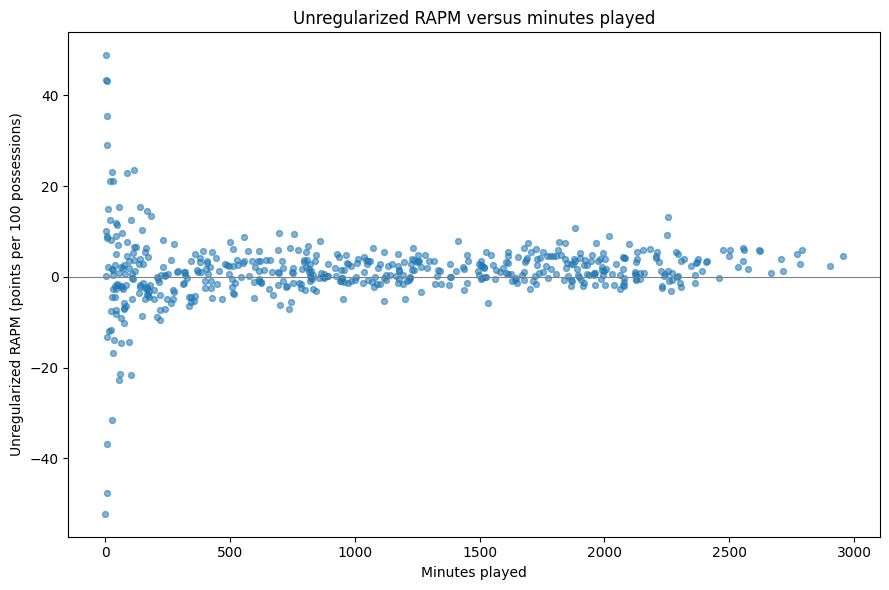

Players without a matched name: 0


In [24]:
player_minutes = (np.abs(X) > 0).T @ nba_stints["minutes"].to_numpy(dtype=float)

unreg_players = pd.DataFrame({
    "player_id": player_ids,
    "RAPM": unregularized.coef_,
    "minutes": player_minutes,
}).merge(player_lookup, on="player_id", how="left", validate="one_to_one")

unreg_players = unreg_players[["player_id", "player_name", "RAPM", "minutes"]]
display(unreg_players.sort_values("RAPM", ascending=False).head(20).round(2))

plt.figure(figsize=(9, 6))
plt.scatter(unreg_players["minutes"], unreg_players["RAPM"], alpha=0.55, s=18)
plt.xlabel("Minutes played")
plt.ylabel("Unregularized RAPM (points per 100 possessions)")
plt.title("Unregularized RAPM versus minutes played")
plt.axhline(0, color="gray", linewidth=0.8)
plt.tight_layout()
plt.show()

print(f"Players without a matched name: {unreg_players['player_name'].isna().sum()}")

The five highest estimates range from 29.03 to 48.85 points per 100 possessions, but each player had fewer than eight minutes of playing time. These rankings do not identify established stars. Nikola Jokić played 2,255.54 minutes and ranks 16th, despite being a leading player who finished second in the [2022–23 MVP voting](https://www.basketball-reference.com/awards/awards_2023.html). The plot also shows that estimates vary widely for players with few minutes. This suggests that the nearly unregularized estimates are strongly affected by limited playing time.

### 1(c) RAPM with Ridge Regression

This part refits the player effects with ridge regression. Its penalty pulls unstable estimates toward zero. Cross validation chooses the penalty size. We can then compare the player rankings and prediction errors with the results from parts (a) and (b).

Ridge regression adds the penalty $\alpha\sum_j\beta_j^2$. This pulls unstable player estimates toward zero but leaves the intercept unpenalized. We test 100 values from $10^{-2}$ to $10^5$, fit the models using possession weights, and use LOOCV to select $\alpha$. We calculate the prediction error with the same weights as in part (a).

Selected alpha: 6280.29
Weighted in-sample RMSE: 45.427
Weighted LOOCV MSE: 2082.747
Weighted LOOCV RMSE: 45.637
LOOCV MSE reduction from part (a): 1.14%


,player_id,player_name,RAPM,minutes
258,203999,Nikola Jokic,2.98,2255.54
2,203110,Draymond Green,2.86,2019.37
156,203954,Joel Embiid,2.75,2249.47
243,201950,Jrue Holiday,2.66,2097.00
306,202695,Kawhi Leonard,2.49,1817.22
244,203507,Giannis Antetokounmpo,2.44,1840.59
167,203076,Anthony Davis,2.28,1880.81
257,203932,Aaron Gordon,2.22,1966.73
198,1628404,Josh Hart,2.20,2474.72
105,1631132,Christian Koloko,2.06,757.82


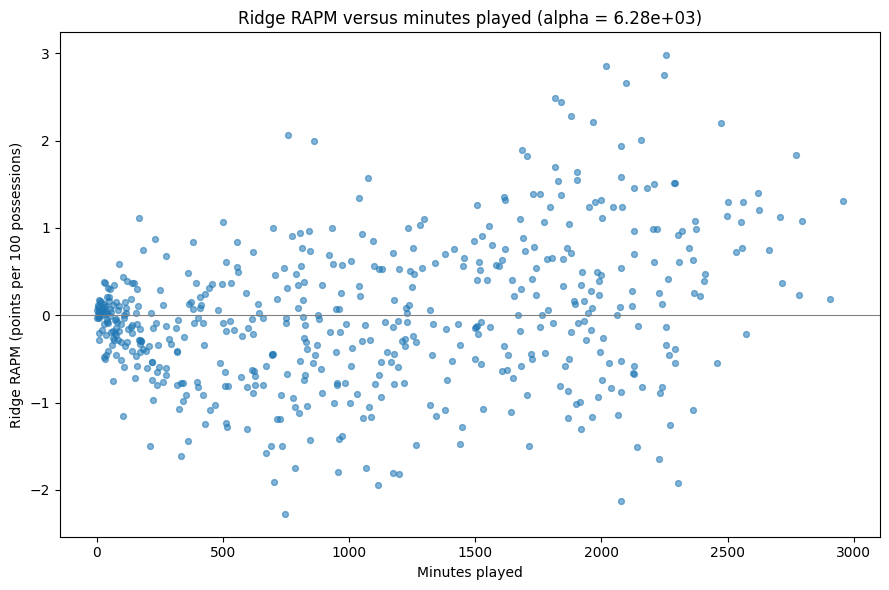

Players without a matched name: 0


In [25]:
ridge_alphas = np.logspace(-2, 5, 100)
ridge_tuning = RidgeCV(
    alphas=ridge_alphas,
    fit_intercept=True,
    scoring=None,
    cv=None,
).fit(X, y, sample_weight=sample_weight)

ridge_alpha = float(ridge_tuning.alpha_)
ridge_model = RidgeCV(
    alphas=[ridge_alpha],
    fit_intercept=True,
    scoring=None,
    cv=None,
    store_cv_results=True,
).fit(X, y, sample_weight=sample_weight)

ridge_train_prediction = ridge_model.predict(X)
ridge_train_mse = np.average(
    (y - ridge_train_prediction) ** 2,
    weights=sample_weight,
)
ridge_loo_weighted_squared_errors = np.asarray(ridge_model.cv_results_).reshape(-1)
ridge_loo_mse = ridge_loo_weighted_squared_errors.sum() / sample_weight.sum()
mse_reduction = 100 * (unreg_loo_mse - ridge_loo_mse) / unreg_loo_mse

ridge_players = pd.DataFrame({
    "player_id": player_ids,
    "RAPM": ridge_model.coef_,
    "minutes": player_minutes,
}).merge(player_lookup, on="player_id", how="left", validate="one_to_one")
ridge_players = ridge_players[["player_id", "player_name", "RAPM", "minutes"]]

print(f"Selected alpha: {ridge_alpha:.6g}")
print(f"Weighted in-sample RMSE: {np.sqrt(ridge_train_mse):.3f}")
print(f"Weighted LOOCV MSE: {ridge_loo_mse:.3f}")
print(f"Weighted LOOCV RMSE: {np.sqrt(ridge_loo_mse):.3f}")
print(f"LOOCV MSE reduction from part (a): {mse_reduction:.2f}%")
display(ridge_players.sort_values("RAPM", ascending=False).head(20).round(2))

plt.figure(figsize=(9, 6))
plt.scatter(ridge_players["minutes"], ridge_players["RAPM"], alpha=0.55, s=18)
plt.xlabel("Minutes played")
plt.ylabel("Ridge RAPM (points per 100 possessions)")
plt.title(f"Ridge RAPM versus minutes played (alpha = {ridge_alpha:.3g})")
plt.axhline(0, color="gray", linewidth=0.8)
plt.tight_layout()
plt.show()

print(f"Players without a matched name: {ridge_players['player_name'].isna().sum()}")

The selected penalty is $\alpha=6{,}280.29$. The weighted LOOCV RMSE is 45.64, compared with 45.90 for the nearly unregularized model. The weighted LOOCV MSE falls by 1.14%, and the training RMSE is 45.43. The largest ridge RAPM is 2.98, compared with 48.85 without meaningful regularization. The top 20 includes players with substantial playing time, including Nikola Jokić, Draymond Green, Joel Embiid, Jrue Holiday, Kawhi Leonard, Giannis Antetokounmpo, and Anthony Davis. Draymond Green and Jrue Holiday were also named to the NBA's defensive teams in the [2022–23 awards voting](https://www.basketball-reference.com/awards/awards_2023.html). Ridge produces less extreme estimates, but these still come from one model and one season.

## Problem 2: Comparing Ridge to Lasso

Ridge regression shrinks coefficients but usually keeps them all nonzero. Lasso uses an absolute value penalty and can set some coefficients to zero. Its weighted objective is

$$
\sum_{i=1}^{n} n_{\mathrm{pos},i}
\left(\mathrm{margin}_i-\beta_0-\sum_{j=1}^{p}c_{ij}\beta_j\right)^2
+\alpha\sum_{j=1}^{p}|\beta_j|,
$$

The intercept is not penalized. We use five fold cross validation to select Lasso's penalty from 100 values between $10^{-4}$ and $10^2$. Each stint is weighted by its number of possessions. We compare the player rankings and coefficient differences with the ridge model from Problem 1(c).

In [26]:
from sklearn.linear_model import LassoCV
from sklearn.model_selection import KFold

lasso_alphas = np.logspace(-4, 2, 100)
lasso_cv = LassoCV(
    alphas=lasso_alphas,
    cv=KFold(n_splits=5, shuffle=True, random_state=622),
    fit_intercept=True,
    max_iter=10_000,
    tol=1e-4,
    n_jobs=-1,
).fit(X, y, sample_weight=sample_weight)

lasso_players = pd.DataFrame({
    "player_id": player_ids,
    "ridge_RAPM": ridge_model.coef_,
    "lasso_RAPM": lasso_cv.coef_,
    "minutes": player_minutes,
}).merge(player_lookup, on="player_id", how="left", validate="one_to_one")
lasso_players["ridge_minus_lasso"] = lasso_players["ridge_RAPM"] - lasso_players["lasso_RAPM"]

ridge_top20_ids = set(lasso_players.nlargest(20, "ridge_RAPM")["player_id"])
lasso_top20_ids = set(lasso_players.nlargest(20, "lasso_RAPM")["player_id"])
top20_overlap = len(ridge_top20_ids & lasso_top20_ids)

print(f"Selected Lasso alpha: {lasso_cv.alpha_:.6g}")
print(f"Nonzero Lasso coefficients: {np.count_nonzero(lasso_cv.coef_)} of {len(player_ids)}")
print(f"Players shared by the Ridge and Lasso top 20: {top20_overlap}")
print("Top 20 by Ridge RAPM:")
display(lasso_players.nlargest(20, "ridge_RAPM")[
    ["player_name", "ridge_RAPM", "lasso_RAPM", "minutes"]
].round(2))
print("Top 20 by Lasso RAPM:")
display(lasso_players.nlargest(20, "lasso_RAPM")[
    ["player_name", "ridge_RAPM", "lasso_RAPM", "minutes"]
].round(2))
print("Largest differences where Ridge RAPM exceeds Lasso RAPM:")
display(lasso_players.nlargest(10, "ridge_minus_lasso")[
    ["player_name", "ridge_RAPM", "lasso_RAPM", "ridge_minus_lasso", "minutes"]
].round(2))
print("Largest differences where Lasso RAPM exceeds Ridge RAPM:")
display(lasso_players.nsmallest(10, "ridge_minus_lasso")[
    ["player_name", "ridge_RAPM", "lasso_RAPM", "ridge_minus_lasso", "minutes"]
].round(2))

Selected Lasso alpha: 0.0464159
Nonzero Lasso coefficients: 100 of 539
Players shared by the Ridge and Lasso top 20: 16
Top 20 by Ridge RAPM:


,player_name,ridge_RAPM,lasso_RAPM,minutes
258,Nikola Jokic,2.98,4.69,2255.54
2,Draymond Green,2.86,4.51,2019.37
156,Joel Embiid,2.75,4.97,2249.47
243,Jrue Holiday,2.66,3.14,2097.00
306,Kawhi Leonard,2.49,2.95,1817.22
244,Giannis Antetokounmpo,2.44,2.46,1840.59
167,Anthony Davis,2.28,2.76,1880.81
257,Aaron Gordon,2.22,2.07,1966.73
198,Josh Hart,2.20,2.88,2474.72
105,Christian Koloko,2.06,2.65,757.82


Top 20 by Lasso RAPM:


,player_name,ridge_RAPM,lasso_RAPM,minutes
156,Joel Embiid,2.75,4.97,2249.47
258,Nikola Jokic,2.98,4.69,2255.54
2,Draymond Green,2.86,4.51,2019.37
243,Jrue Holiday,2.66,3.14,2097.00
306,Kawhi Leonard,2.49,2.95,1817.22
198,Josh Hart,2.20,2.88,2474.72
167,Anthony Davis,2.28,2.76,1880.81
16,Derrick White,1.94,2.75,2078.65
105,Christian Koloko,2.06,2.65,757.82
15,Jayson Tatum,1.83,2.51,2771.44


Largest differences where Ridge RAPM exceeds Lasso RAPM:


,player_name,ridge_RAPM,lasso_RAPM,ridge_minus_lasso,minutes
195,Damian Lillard,1.24,0.00,1.24,2047.00
235,Franz Wagner,1.51,0.34,1.17,2293.49
154,James Harden,1.30,0.14,1.16,1974.74
439,Dennis Schroder,1.38,0.23,1.14,1841.48
344,Boban Marjanovic,1.11,0.00,1.11,166.57
417,Myles Turner,1.11,0.00,1.11,1676.32
296,Paul George,1.07,0.00,1.07,1771.55
20,Blake Griffin,1.06,0.00,1.06,501.85
0,Stephen Curry,1.05,0.00,1.05,1873.19
212,Delon Wright,0.99,0.00,0.99,1234.00


Largest differences where Lasso RAPM exceeds Ridge RAPM:


,player_name,ridge_RAPM,lasso_RAPM,ridge_minus_lasso,minutes
156,Joel Embiid,2.75,4.97,-2.22,2249.47
258,Nikola Jokic,2.98,4.69,-1.72,2255.54
2,Draymond Green,2.86,4.51,-1.65,2019.37
255,Thanasis Antetokounmpo,-1.50,-0.00,-1.50,208.71
185,Josh Christopher,-1.50,-0.07,-1.43,734.98
150,Gorgui Dieng,-1.44,-0.06,-1.39,362.05
6,JaMychal Green,-1.43,-0.06,-1.37,843.66
125,Day'Ron Sharpe,-1.30,-0.00,-1.30,596.00
464,Ziaire Williams,-1.28,-0.00,-1.28,514.49
214,Daniel Gafford,-1.28,-0.01,-1.27,1448.27


The two models have 16 players in common in their top 20. Lasso keeps 100 of the 539 coefficients and sets the rest to zero, while ridge keeps every coefficient. Among the largest differences, ridge gives Stephen Curry and Damian Lillard positive estimates (1.05 and 1.24), while lasso gives both zero. In 2023–24, Curry averaged 26.4 points per game and Lillard averaged 24.3, which makes ridge's positive estimates more consistent with their continued scoring than lasso's zero estimates. In the other direction, lasso estimates higher RAPM than ridge for Joel Embiid (4.97 versus 2.75), Nikola Jokić (4.69 versus 2.98), and Draymond Green (4.51 versus 2.86). Embiid averaged 34.7 points per game in 39 games, and Jokić averaged 26.4 points per game and won the MVP award. Those results are consistent with strong positive contributions, although they do not establish that lasso's larger values are more accurate. Points per game are not RAPM and do not account for teammates, opponents, or defense. The next season's scoring gives some support to ridge for Curry and Lillard and to lasso's larger estimates for Embiid and Jokić, but it cannot establish which model better estimates adjusted contribution. Source: [Basketball Reference's 2023–24 season statistics](https://www.basketball-reference.com/leagues/NBA_2024_per_game.html).

## Problem 3: Bootstrap for Parameter Uncertainty

The ridge estimates use regularization. To see how much they might change with different stints, we sample the stints with replacement and refit ridge using the penalty selected in Problem 1(c). Each sampled stint keeps its possession weight. We keep the penalty fixed, so this measures variation due to resampling the stints only.

### 3(a) Bootstrap confidence intervals

We use 500 bootstrap samples. For player $j$, the 4th and 96th percentiles of the resampled coefficients form the 92% interval:

$$
\left[Q_{0.04}(\widehat{\beta}_j^*),\;Q_{0.96}(\widehat{\beta}_j^*)\right].
$$

The table shows intervals for the 20 players with the highest ridge RAPM. We also count the overlapping pairs of intervals.

Bootstrap resamples: 500
Overlapping 92% CI pairs among the top 20: 190 of 190


,player_name,RAPM,bootstrap_92_lower,bootstrap_92_upper,minutes
258,Nikola Jokic,2.98,1.94,3.95,2255.54
2,Draymond Green,2.86,1.51,4.06,2019.37
156,Joel Embiid,2.75,1.63,3.77,2249.47
243,Jrue Holiday,2.66,1.46,3.82,2097.00
306,Kawhi Leonard,2.49,1.27,3.72,1817.22
244,Giannis Antetokounmpo,2.44,1.10,3.82,1840.59
167,Anthony Davis,2.28,1.03,3.54,1880.81
257,Aaron Gordon,2.22,1.33,3.37,1966.73
198,Josh Hart,2.20,0.88,3.61,2474.72
105,Christian Koloko,2.06,0.67,3.40,757.82


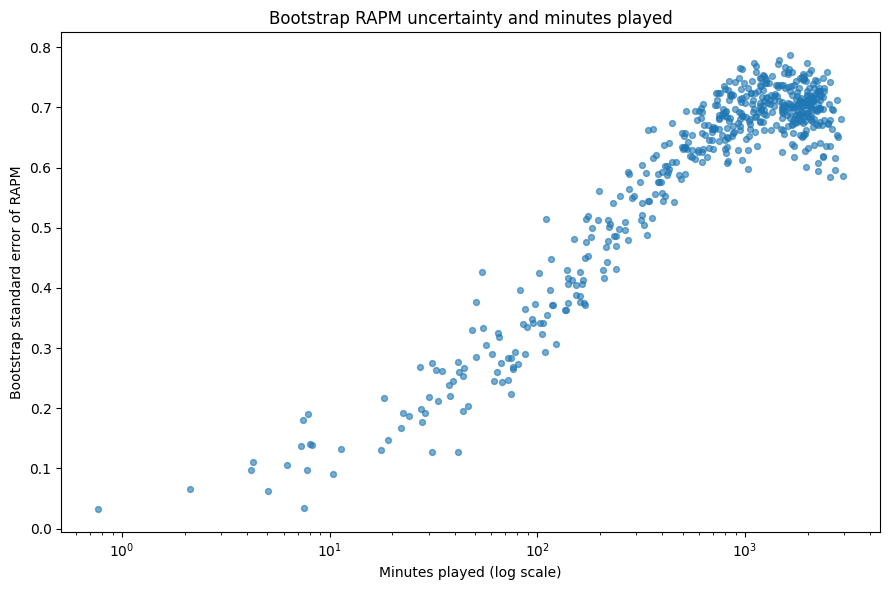

Spearman correlation between log(1 + minutes) and bootstrap SE: 0.738
Players with zero minutes in this dataset: 0


In [27]:
from scipy.sparse import csr_matrix
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge

X_sparse = csr_matrix(X)
bootstrap_replicates = 500
bootstrap_rng = np.random.default_rng(622)
bootstrap_coefs = np.empty((bootstrap_replicates, X.shape[1]))
bootstrap_ridge = Ridge(
    alpha=ridge_alpha,
    fit_intercept=True,
    solver="lsqr",
    tol=1e-6,
    max_iter=2_000,
)

for b in range(bootstrap_replicates):
    sample_index = bootstrap_rng.integers(0, len(y), size=len(y))
    bootstrap_ridge.fit(
        X_sparse[sample_index],
        y[sample_index],
        sample_weight=sample_weight[sample_index],
    )
    bootstrap_coefs[b] = bootstrap_ridge.coef_

bootstrap_se = bootstrap_coefs.std(axis=0, ddof=1)
bootstrap_lower, bootstrap_upper = np.quantile(bootstrap_coefs, [0.04, 0.96], axis=0)
bootstrap_results = ridge_players.copy()
bootstrap_results["bootstrap_SE"] = bootstrap_se
bootstrap_results["bootstrap_92_lower"] = bootstrap_lower
bootstrap_results["bootstrap_92_upper"] = bootstrap_upper

top20_bootstrap = bootstrap_results.nlargest(20, "RAPM").copy()
top20_lower = top20_bootstrap["bootstrap_92_lower"].to_numpy()
top20_upper = top20_bootstrap["bootstrap_92_upper"].to_numpy()
overlap_matrix = (top20_lower[:, None] <= top20_upper[None, :]) & (top20_lower[None, :] <= top20_upper[:, None])
overlapping_pairs = int(np.triu(overlap_matrix, k=1).sum())
possible_pairs = 20 * 19 // 2

print(f"Bootstrap resamples: {bootstrap_replicates}")
print(f"Overlapping 92% CI pairs among the top 20: {overlapping_pairs} of {possible_pairs}")
display(top20_bootstrap[[
    "player_name", "RAPM", "bootstrap_92_lower", "bootstrap_92_upper", "minutes"
]].round(2))

plt.figure(figsize=(9, 6))
plt.scatter(bootstrap_results["minutes"], bootstrap_results["bootstrap_SE"], alpha=0.6, s=18)
plt.xscale("log")
plt.xlabel("Minutes played (log scale)")
plt.ylabel("Bootstrap standard error of RAPM")
plt.title("Bootstrap RAPM uncertainty and minutes played")
plt.tight_layout()
plt.show()

spearman_minutes_se = spearmanr(
    np.log1p(bootstrap_results["minutes"]),
    bootstrap_results["bootstrap_SE"],
)
print(f"Spearman correlation between log(1 + minutes) and bootstrap SE: {spearman_minutes_se.statistic:.3f}")
print(f"Players with zero minutes in this dataset: {(player_minutes == 0).sum()}")

All 190 pairs of intervals for the top 20 overlap, so the bootstrap does not give a clear order for those players.

### 3(b) Minutes and bootstrap standard errors

In this fit, standard errors increase with minutes. The Spearman correlation between log(1 + minutes) and standard error is 0.738. This is not the pattern we might expect: more playing time usually provides more information. Here, the fixed ridge penalty keeps estimates for players with few minutes close to zero across resamples. Their small bootstrap variation does not mean we know their ability precisely. If a player were absent from every stint, every bootstrap estimate would be zero, giving a misleading interval of $[0,0]$ and a standard error of zero. This dataset has no players with zero minutes.

### 3(c) Bayesian credible intervals

We assume a Gaussian model with variance $\sigma^2/n_{\mathrm{pos},i}$ and a normal prior centered at zero for the player coefficients. The posterior covariance is $\sigma^2(X_c^T W X_c+\alpha I)^{-1}$, where $X_c$ is the player design matrix after weighted centering. Centering accounts for the unpenalized intercept. We estimate $\sigma^2$ from the weighted residual sum of squares and residual degrees of freedom, then calculate normal 92% credible intervals:

$$
\widehat{\beta}_j \pm z_{0.96}\,\mathrm{SE}_{\mathrm{Bayes},j}.
$$

These intervals reflect the ridge prior. They are not the same as the bootstrap intervals.

Estimated residual variance: 16471.109


,player_name,RAPM,bootstrap_SE,bayesian_SE,bayesian_92_lower,bayesian_92_upper,minutes
258,Nikola Jokic,2.98,0.60,1.28,0.73,5.22,2255.54
2,Draymond Green,2.86,0.71,1.23,0.71,5.02,2019.37
156,Joel Embiid,2.75,0.61,1.25,0.57,4.94,2249.47
243,Jrue Holiday,2.66,0.68,1.21,0.54,4.78,2097.00
306,Kawhi Leonard,2.49,0.69,1.22,0.36,4.63,1817.22
244,Giannis Antetokounmpo,2.44,0.75,1.20,0.34,4.55,1840.59
167,Anthony Davis,2.28,0.70,1.22,0.14,4.43,1880.81
257,Aaron Gordon,2.22,0.60,1.29,-0.04,4.47,1966.73
198,Josh Hart,2.20,0.76,1.15,0.20,4.21,2474.72
105,Christian Koloko,2.06,0.72,1.35,-0.30,4.43,757.82


Five players with the fewest minutes:


,player_name,RAPM,bootstrap_SE,bayesian_SE,bayesian_92_lower,bayesian_92_upper,minutes
446,Michael Foster Jr.,-0.03,0.03,1.62,-2.87,2.80,0.77
533,Stanley Umude,0.06,0.07,1.62,-2.77,2.89,2.12
530,Alondes Williams,0.02,0.10,1.62,-2.81,2.85,4.19
535,Donovan Williams,0.12,0.11,1.62,-2.71,2.95,4.25
534,Frank Jackson,-0.01,0.06,1.62,-2.85,2.82,5.05


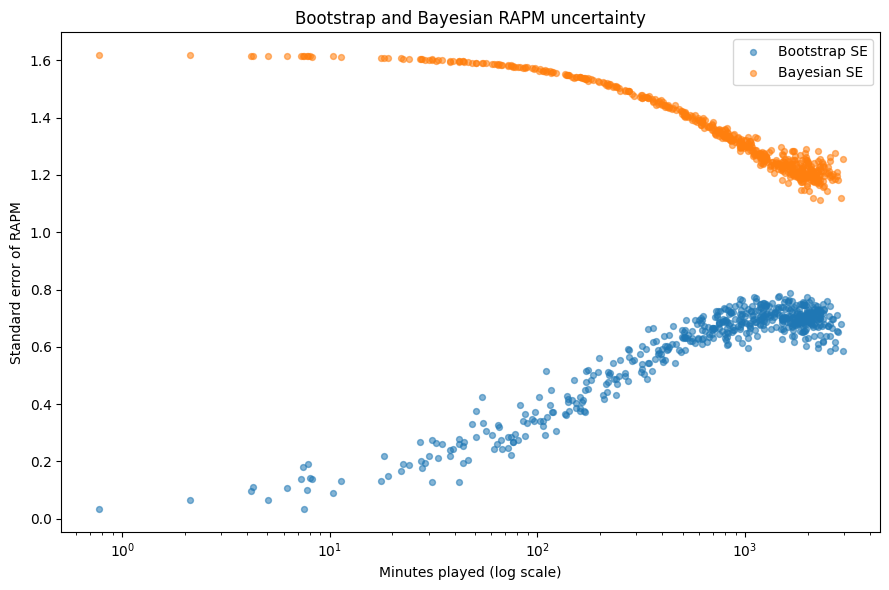

Median bootstrap SE: 0.672
Median Bayesian SE: 1.311


In [28]:
from scipy.linalg import cho_factor, cho_solve
from scipy.stats import norm

def bayesian_rapm_uncertainty(design, response, weights, fitted_model, alpha):
    player_count = design.shape[1]
    weight_sum = weights.sum()
    residuals = response - fitted_model.predict(design)
    residual_variance = np.sum(weights * residuals**2) / (len(response) - player_count - 1)

    weighted_column_sums = np.asarray(design.T @ weights).reshape(-1)
    weighted_gram = (design.T @ design.multiply(weights[:, None])).toarray()
    centered_gram = weighted_gram - np.outer(weighted_column_sums, weighted_column_sums) / weight_sum
    posterior_precision = centered_gram + alpha * np.eye(player_count)
    factor = cho_factor(posterior_precision, lower=True, check_finite=False)
    posterior_covariance = residual_variance * cho_solve(
        factor,
        np.eye(player_count),
        check_finite=False,
    )
    standard_errors = np.sqrt(np.diag(posterior_covariance))
    return residual_variance, standard_errors

residual_variance, bayesian_se = bayesian_rapm_uncertainty(
    X_sparse, y, sample_weight, ridge_model, ridge_alpha
)
credible_z = norm.ppf(0.96)
ridge_players["bayesian_SE"] = bayesian_se
ridge_players["bayesian_92_lower"] = ridge_model.coef_ - credible_z * bayesian_se
ridge_players["bayesian_92_upper"] = ridge_model.coef_ + credible_z * bayesian_se
ridge_players["bootstrap_SE"] = bootstrap_se

comparison = ridge_players.nlargest(20, "RAPM")[[
    "player_name", "RAPM", "bootstrap_SE", "bayesian_SE",
    "bayesian_92_lower", "bayesian_92_upper", "minutes",
]]
print(f"Estimated residual variance: {residual_variance:.3f}")
display(comparison.round(2))
print("Five players with the fewest minutes:")
display(ridge_players.nsmallest(5, "minutes")[
    ["player_name", "RAPM", "bootstrap_SE", "bayesian_SE", "bayesian_92_lower", "bayesian_92_upper", "minutes"]
].round(2))

plt.figure(figsize=(9, 6))
plt.scatter(ridge_players["minutes"], ridge_players["bootstrap_SE"], alpha=0.55, s=18, label="Bootstrap SE")
plt.scatter(ridge_players["minutes"], ridge_players["bayesian_SE"], alpha=0.55, s=18, label="Bayesian SE")
plt.xscale("log")
plt.xlabel("Minutes played (log scale)")
plt.ylabel("Standard error of RAPM")
plt.title("Bootstrap and Bayesian RAPM uncertainty")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Median bootstrap SE: {np.median(bootstrap_se):.3f}")
print(f"Median Bayesian SE: {np.median(bayesian_se):.3f}")

For a general manager, a wide interval means the estimate is uncertain and should not be treated as a precise ranking. The median Bayesian standard error is 1.311, compared with 0.672 for the bootstrap, so the Bayesian intervals are wider in this fit. For example, Michael Foster Jr. played 0.77 minutes. His bootstrap standard error is 0.03, while his Bayesian standard error is 1.62 and his Bayesian 92% interval is $[-2.87, 2.80]$. The narrow bootstrap result comes partly from keeping the ridge penalty fixed: his estimate changes little across resamples. A general manager should not interpret that small bootstrap error as proof of low uncertainty. The wider Bayesian interval signals that his contribution is uncertain. Neither method accounts for uncertainty in the penalty chosen by cross validation, so more evidence would be needed before making a decision based on either interval.

## Extra Credit: Coverage

The course provides one simulated season of margins and the true RAPM values used to create them. We tune ridge on these margins, then calculate bootstrap intervals from 100 samples and Bayesian intervals from the ridge posterior approximation. Both methods use the penalty selected from the simulated margins. Coverage is the share of the 539 true player values that fall within each method's 92% intervals.

In [29]:
sim_base_url = "https://raw.githubusercontent.com/georgehagstrom/DATA622Fall2026/main/website/assignments/labs/labData/"
simulated_margins = pd.read_csv(sim_base_url + "nba_stint_margin_sim.csv")
true_rapm = pd.read_csv(sim_base_url + "nba_true_rapm_sim.csv")

simulated_stints = nba_stints[["game_id", "stint_id"]].merge(
    simulated_margins,
    on=["game_id", "stint_id"],
    how="left",
    validate="one_to_one",
)
if simulated_stints["margin_sim"].isna().any():
    raise ValueError("Some stint rows did not match the simulated margins.")

y_sim = simulated_stints["margin_sim"].to_numpy(dtype=float)
simulation_model = RidgeCV(
    alphas=ridge_alphas,
    fit_intercept=True,
    scoring=None,
    cv=None,
).fit(X_sparse, y_sim, sample_weight=sample_weight)
simulation_alpha = float(simulation_model.alpha_)
simulation_ridge = Ridge(
    alpha=simulation_alpha,
    fit_intercept=True,
    solver="lsqr",
    tol=1e-6,
    max_iter=2_000,
).fit(X_sparse, y_sim, sample_weight=sample_weight)

true_rapm_aligned = true_rapm.set_index("player_id").reindex(player_ids)
if true_rapm_aligned["true_rapm"].isna().any():
    raise ValueError("Some player columns did not match a supplied true RAPM value.")
true_coefficients = true_rapm_aligned["true_rapm"].to_numpy(dtype=float)

simulation_bootstrap_replicates = 100
simulation_rng = np.random.default_rng(623)
simulation_bootstrap_coefs = np.empty((simulation_bootstrap_replicates, X.shape[1]))
simulation_bootstrap_ridge = Ridge(
    alpha=simulation_alpha,
    fit_intercept=True,
    solver="lsqr",
    tol=1e-6,
    max_iter=2_000,
)
for b in range(simulation_bootstrap_replicates):
    sample_index = simulation_rng.integers(0, len(y_sim), size=len(y_sim))
    simulation_bootstrap_coefs[b] = simulation_bootstrap_ridge.fit(
        X_sparse[sample_index],
        y_sim[sample_index],
        sample_weight=sample_weight[sample_index],
    ).coef_

simulation_bootstrap_lower, simulation_bootstrap_upper = np.quantile(
    simulation_bootstrap_coefs, [0.04, 0.96], axis=0
)
simulation_variance, simulation_bayesian_se = bayesian_rapm_uncertainty(
    X_sparse, y_sim, sample_weight, simulation_ridge, simulation_alpha
)
simulation_z = norm.ppf(0.96)
simulation_bayesian_lower = simulation_ridge.coef_ - simulation_z * simulation_bayesian_se
simulation_bayesian_upper = simulation_ridge.coef_ + simulation_z * simulation_bayesian_se

bootstrap_coverage = np.mean(
    (simulation_bootstrap_lower <= true_coefficients)
    & (true_coefficients <= simulation_bootstrap_upper)
)
bayesian_coverage = np.mean(
    (simulation_bayesian_lower <= true_coefficients)
    & (true_coefficients <= simulation_bayesian_upper)
)
print(f"Selected simulation alpha: {simulation_alpha:.6g}")
print(f"Bootstrap 92% interval coverage: {bootstrap_coverage:.1%} ({bootstrap_coverage * len(player_ids):.0f} of {len(player_ids)} coefficients)")
print(f"Bayesian 92% credible interval coverage: {bayesian_coverage:.1%} ({bayesian_coverage * len(player_ids):.0f} of {len(player_ids)} coefficients)")
print(f"Distance from nominal 92%: bootstrap {abs(bootstrap_coverage - 0.92):.1%}; Bayesian {abs(bayesian_coverage - 0.92):.1%}")

Selected simulation alpha: 5336.7
Bootstrap 92% interval coverage: 55.8% (301 of 539 coefficients)
Bayesian 92% credible interval coverage: 89.1% (480 of 539 coefficients)
Distance from nominal 92%: bootstrap 36.2%; Bayesian 2.9%


The selected penalty is $\alpha=5{,}336.7$. Bootstrap intervals contain 301 of the 539 true coefficients (55.8%), while Bayesian intervals contain 480 (89.1%). In this simulation, Bayesian coverage is closer to the expected 92%. This result is not a general guarantee. It comes from one simulated season, and player coefficients are related. The bootstrap also keeps the selected penalty fixed, while ridge pulls estimates toward zero. The intervals are used to make claims about the true coefficients even though the estimates are shrunk and the penalty was chosen using the same data. A stronger coverage study would repeat the simulation many times and account for penalty selection.